# Population coding: cosine tuning, Poisson noise and decoding

## Question

 **Why can a population of neurons tell stimuli apart when a single neuron cannot?**

We simulate a small population of direction-tuned neurons, look at the population response in two ways (heatmap and PCA), and then ask a decoder to recover the stimulus from single trials, first with one neuron, then with many.

```text
stimulus direction θ
        ↓
cosine tuning curve  f_i(θ)        (one per neuron)
        ↓
Poisson spike count  n_i ~ Poisson(f_i(θ)·T)
        ↓
population vector  [n_1, …, n_50]  (one per trial)
        ↓
heatmap · PCA · cross-validated decoder
        ↓
1 neuron vs population   (optional: + noise correlations)
```

| Section | What it does | Figure |
|---|---|---|
| 1 | Simulate 50 cosine-tuned neurons, 8 directions, Poisson counts | fig01_tuning_curves.png |
| 2 | Heatmap of mean and single-trial responses | fig02_heatmap.png |
| 3 | PCA of the population patterns | fig03_pca.png |
| 4 | Decoder with stratified cross-validation + permutation test | fig04_decoder.png |
| 5 | One neuron vs the population | fig05_single_vs_population.png |
| 6 | Vary noise correlations | fig06–fig08 |

**Reproducibility.** Every random number comes from one seed (SEED), split into independent streams per section. Run the notebook top to bottom (*Restart & Run All*); re-running single cells advances the random streams and changes the numbers. Total run time is about one to two minutes on a laptop.

## 0. Setup

In [18]:
from pathlib import Path
import platform
import warnings

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_val_score, permutation_test_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print(f"Python {platform.python_version()} | NumPy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | Matplotlib {mpl.__version__}")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

Python 3.11.9 | NumPy 2.4.6 | scikit-learn 1.9.1 | Matplotlib 3.11.2


In [19]:
# Plot style: light surface, hairline grid, thin marks 
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

# Fixed colour per condition, used the same way in every figure (never cycled).
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

# Sequential (magnitude): one hue, light → dark.
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", [SURFACE, "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
# Diverging (signed values): blue ↔ red with a neutral grey midpoint.
DIV = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8584", "#c23434"])
# Cyclic (direction is a circular variable: 0° and 360° are the same stimulus).
CYC = plt.get_cmap("twilight_shifted")

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 10, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 1.6, "lines.markersize": 6,
    "legend.frameon": False, "legend.fontsize": 9,
})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    print(f"saved → {path}")


def chance_line(ax, chance, label=True):
    ax.axhline(chance, color=MUTED, lw=1)
    if label:
        ax.annotate(f"chance = 1/{round(1 / chance)}", xy=(1, chance), xycoords=("axes fraction", "data"),
                    xytext=(0, 4), textcoords="offset points", ha="right", va="bottom",
                    fontsize=8.5, color=MUTED)

In [20]:
# Parameters 
SEED = 2026

P = {
    # population and stimuli
    "n_neurons": 50,
    "n_stimuli": 8,              # 4–8 directions, equally spaced on [0°, 360°)
    "n_trials": 60,              # trials per stimulus
    "window_s": 0.2,             # spike-counting window (s)
    "baseline_hz": (2.0, 10.0),  # b_i ~ Uniform(...)
    "gain_hz": (10.0, 30.0),     # g_i ~ Uniform(...)
    # decoding
    "cv_folds": 5,
    "n_permutations": 200,
    "subset_sizes": [1, 2, 4, 8, 16, 32, 50],
    "n_subset_draws": 20,
    # optional section: noise correlations
    "latent_sigma": 0.5,         # SD of the shared log-rate fluctuation (same in every condition)
    "rho_values": [0.0, 0.1, 0.2, 0.4, 0.6],
    "limited_range_width": 0.5,  # how fast correlation falls with preferred-direction difference
    "n_corr_repeats": 5,         # simulated datasets per (structure, rho)
    "rho_for_curves": 0.4,       # rho used in Figures 6 and 8
    "n_subset_draws_corr": 10,
}

rng_pop, rng_data, rng_corr, rng_sub = (np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(4))
CV = StratifiedKFold(n_splits=P["cv_folds"], shuffle=True, random_state=SEED)

## 1. The model: cosine tuning + Poisson spike counts

Each neuron $i$ has a **preferred direction** $\varphi_i$, a **baseline** rate $b_i$ and a **gain** $g_i$. Its mean firing rate for a stimulus moving in direction $\theta$ is a cosine tuning curve:

$$
f_i(\theta) = b_i + g_i \,\frac{1 + \cos(\theta - \varphi_i)}{2}
\qquad\Rightarrow\qquad b_i \le f_i(\theta) \le b_i + g_i .
$$

This is the tuning shape Georgopoulos and colleagues described for motor-cortex neurons and arm-movement direction: the response peaks at $\varphi_i$ and falls off smoothly and symmetrically on both sides.

On each trial the stimulus is shown for a window of $T$ seconds and we record the **spike count**:

$$
n_i \sim \text{Poisson}\big(f_i(\theta)\,T\big), \qquad \mathbb{E}[n_i] = \operatorname{Var}[n_i] = f_i(\theta)\,T .
$$

So the noise is **private** (each neuron draws independently) and its variance grows with the mean (Fano factor = 1).

| Item | Value |
|---|---|
| Neurons $N$ | 50, $\varphi_i \sim U(0°, 360°)$ |
| Baseline $b_i$, gain $g_i$ | $U(2, 10)$ Hz, $U(10, 30)$ Hz |
| Stimuli $K$ | 8 directions: 0°, 45°, …, 315° |
| Trials | 60 per stimulus (480 in total) |
| Window $T$ | 0.2 s → roughly 0.4 to 8 spikes per trial |

In [21]:
def make_population(n_neurons, baseline_hz, gain_hz, rng):
    # Random cosine-tuned population: preferred direction, baseline and gain per neuron.
    return {
        "pref": rng.uniform(0, 2 * np.pi, n_neurons),
        "baseline": rng.uniform(*baseline_hz, n_neurons),
        "gain": rng.uniform(*gain_hz, n_neurons),
    }


def tuning(theta, pop):
    # Mean firing rate in Hz, shape (len(theta), n_neurons).
    theta = np.atleast_1d(theta)[:, None]
    return pop["baseline"] + pop["gain"] * (1 + np.cos(theta - pop["pref"])) / 2


def simulate_counts(pop, stimuli, n_trials, window_s, rng):
    # Independent Poisson counts. X: (trials × neurons); y: stimulus index of each trial.
    y = np.repeat(np.arange(len(stimuli)), n_trials)
    X = rng.poisson(tuning(stimuli, pop)[y] * window_s).astype(float)
    return X, y


pop = make_population(P["n_neurons"], P["baseline_hz"], P["gain_hz"], rng_pop)
K, N, T = P["n_stimuli"], P["n_neurons"], P["window_s"]
stimuli = np.arange(K) * 2 * np.pi / K
stim_deg = np.rad2deg(stimuli).round().astype(int)
CHANCE = 1 / K
order = np.argsort(pop["pref"])            # neurons sorted by preferred direction (for plots)

X, y = simulate_counts(pop, stimuli, P["n_trials"], T, rng_data)
print(f"X: {X.shape[0]} trials × {X.shape[1]} neurons | {K} stimuli × {P['n_trials']} trials | chance = {CHANCE:.3f}")

X: 480 trials × 50 neurons | 8 stimuli × 60 trials | chance = 0.125


In [22]:
# Sanity checks: empirical means match f_i(θ)·T, and variance ≈ mean (Poisson).
expected = tuning(stimuli, pop) * T                                   # K × N
means = np.stack([X[y == k].mean(0) for k in range(K)])
sems = np.stack([X[y == k].std(0, ddof=1) / np.sqrt(P["n_trials"]) for k in range(K)])
variances = np.stack([X[y == k].var(0, ddof=1) for k in range(K)])
fano = variances / means

rel_err = np.abs(means - expected).mean() / expected.mean()
print(f"Expected counts per trial: {expected.min():.2f} to {expected.max():.2f} spikes")
print(f"Mean |empirical − expected| / mean expected: {rel_err:.3f}")
print(f"Median Fano factor (variance / mean): {np.median(fano):.2f}   (Poisson → 1)")
assert rel_err < 0.15 and 0.8 < np.median(fano) < 1.2

Expected counts per trial: 0.51 to 7.70 spikes
Mean |empirical − expected| / mean expected: 0.057
Median Fano factor (variance / mean): 1.00   (Poisson → 1)


saved → figures\fig01_tuning_curves.png


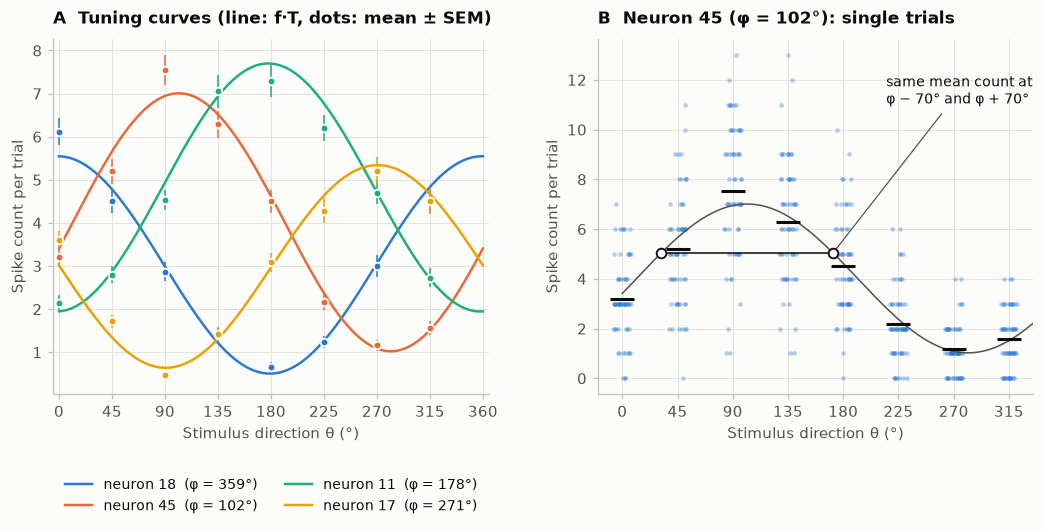

In [23]:
# Four example neurons whose preferred directions are closest to 0°, 90°, 180° and 270°.
def circ_dist(a, b):
    return np.abs(np.angle(np.exp(1j * (a - b))))

examples = []
for target in np.deg2rad([0, 90, 180, 270]):
    d = circ_dist(pop["pref"], target)
    d[examples] = np.inf
    examples.append(int(np.argmin(d)))
colors = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]

# Neuron for panel B: preferred direction closest to the stimulus at 90° (index K//4).
k_peak = K // 4
j_b = int(np.argmin(circ_dist(pop["pref"], stimuli[k_peak])))

theta_dense = np.linspace(0, 2 * np.pi, 361)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"wspace": 0.25})

ax = axes[0]
for j, c in zip(examples, colors):
    ax.plot(np.rad2deg(theta_dense), tuning(theta_dense, pop)[:, j] * T, color=c, lw=1.6,
            label=f"neuron {j}  (φ = {np.rad2deg(pop['pref'][j]):.0f}°)")
    ax.errorbar(stim_deg, means[:, j], yerr=sems[:, j], fmt="o", color=c, ms=5,
                mec=SURFACE, mew=1.2, elinewidth=1, capsize=0)
ax.set(xlabel="Stimulus direction θ (°)", ylabel="Spike count per trial", xlim=(-5, 365),
       xticks=np.arange(0, 361, 45), title="A  Tuning curves (line: f·T, dots: mean ± SEM)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)

ax = axes[1]
jitter = np.random.default_rng(0).uniform(-7, 7, X.shape[0])           # plotting only
ax.scatter(np.rad2deg(stimuli)[y] + jitter, X[:, j_b], s=9, color=C_BLUE, alpha=0.35, lw=0)
ax.plot(np.rad2deg(theta_dense), tuning(theta_dense, pop)[:, j_b] * T, color=INK_2, lw=1)
ax.scatter(stim_deg, means[:, j_b], marker="_", s=260, color=INK, lw=2, zorder=3)
# Symmetry: φ − 70° and φ + 70° give exactly the same mean count.
pair = pop["pref"][j_b] + np.deg2rad([-70, 70])
level = tuning(pair[:1], pop)[0, j_b] * T
ax.plot(np.rad2deg(pair), [level, level], color=INK, lw=1, zorder=4)
ax.scatter(np.rad2deg(pair), [level, level], s=40, facecolor=SURFACE, edgecolor=INK, lw=1.2, zorder=5)
ax.annotate("same mean count at\nφ − 70° and φ + 70°", xy=(np.rad2deg(pair[1]), level),
            xytext=(215, 0.85 * X[:, j_b].max()), fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8))
ax.set(xlabel="Stimulus direction θ (°)", ylabel="Spike count per trial", xlim=(-20, 335),
       xticks=stim_deg, title=f"B  Neuron {j_b} (φ = {np.rad2deg(pop['pref'][j_b]):.0f}°): single trials")
save(fig, "fig01_tuning_curves.png")
plt.show()

**Reading Figure 1.** In panel A each neuron has the same cosine shape, shifted to its own preferred direction, with its own baseline and height. Panel B shows the problem a single neuron has. Two things make its count an unreliable report of the stimulus:

1. **Symmetry.** The cosine is symmetric around $\varphi_i$, so directions at $\varphi_i - \delta$ and $\varphi_i + \delta$ give the *same* mean count (arrows). Even without noise, one neuron cannot say on which side of its preference the stimulus was.
2. **Noise.** With Poisson noise, the spread of counts for one stimulus overlaps heavily with the spread for its neighbours.

## 2. Heatmap of the population response

Two views of the same data:

- **A - trial-averaged.** Mean count of each neuron for each stimulus, divided by that neuron's maximum mean (so all neurons share the 0 - 1 scale). Neurons are sorted by preferred direction.
- **B - single trials.** Every trial (columns, grouped by stimulus) for every neuron (rows, same order), z-scored per neuron.

saved → figures\fig02_heatmap.png


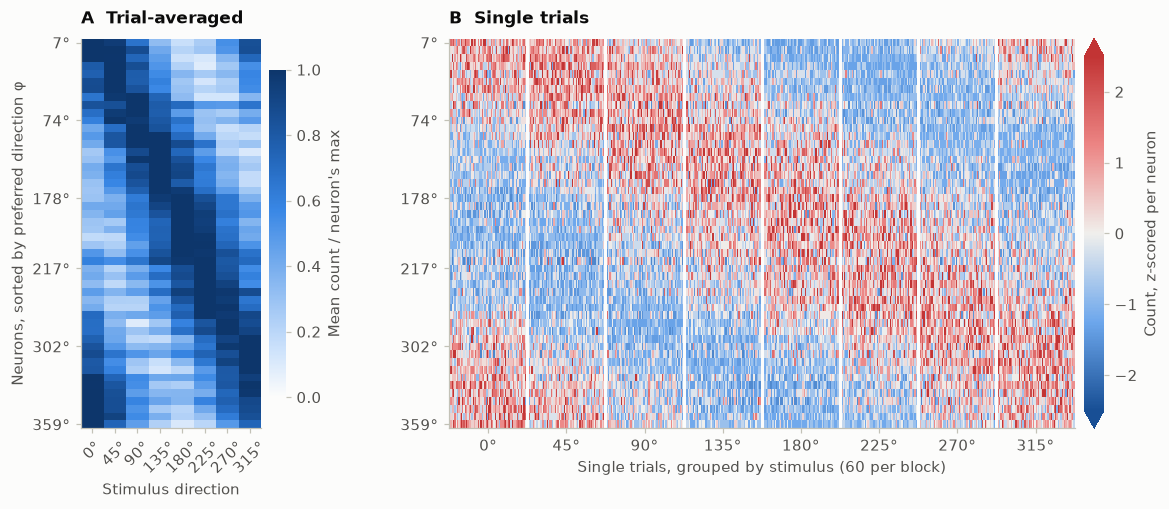

In [24]:
mean_norm = (means / means.max(axis=0)).T[order]                      # N × K, sorted neurons
Z_trials = ((X - X.mean(0)) / X.std(0)).T[order]                      # N × trials, sorted neurons
pref_sorted_deg = np.rad2deg(pop["pref"][order])
ytick_pos = np.linspace(0, N - 1, 6).round().astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 3.2], "wspace": 0.38})

ax = axes[0]
im = ax.imshow(mean_norm, aspect="auto", cmap=SEQ, vmin=0, vmax=1, interpolation="nearest")
ax.set(xticks=range(K), xticklabels=[f"{d}°" for d in stim_deg], yticks=ytick_pos,
       yticklabels=[f"{pref_sorted_deg[i]:.0f}°" for i in ytick_pos],
       xlabel="Stimulus direction", ylabel="Neurons, sorted by preferred direction φ",
       title="A  Trial-averaged")
ax.tick_params(axis="x", labelrotation=45)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.08, pad=0.04)
cb.set_label("Mean count / neuron's max", color=INK_2)
cb.outline.set_visible(False)

ax = axes[1]
lim = 2.5
im = ax.imshow(Z_trials, aspect="auto", cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim), interpolation="nearest")
bounds = np.arange(1, K) * P["n_trials"] - 0.5
for b in bounds:
    ax.axvline(b, color=SURFACE, lw=2)
ax.set(xticks=(np.arange(K) + 0.5) * P["n_trials"] - 0.5, xticklabels=[f"{d}°" for d in stim_deg],
       yticks=ytick_pos, yticklabels=[f"{pref_sorted_deg[i]:.0f}°" for i in ytick_pos],
       xlabel=f"Single trials, grouped by stimulus ({P['n_trials']} per block)",
       title="B  Single trials")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.015, extend="both")
cb.set_label("Count, z-scored per neuron", color=INK_2)
cb.outline.set_visible(False)
save(fig, "fig02_heatmap.png")
plt.show()

**Reading Figure 2.** Because the neurons are sorted by preferred direction, the trial-averaged map (A) shows a **diagonal band** that wraps around: each stimulus activates the neurons tuned near it. The *pattern* across the population, not any single row, identifies the stimulus. In single trials (B) the band is still visible, but each column is noisy; the decoder in Section 4 has to work from one column at a time.

## 3. PCA of the population patterns

Expanding the cosine shows that every tuning curve is a weighted sum of the same three functions of $\theta$:

$$
f_i(\theta) = \Big(b_i + \tfrac{g_i}{2}\Big)
+ \tfrac{g_i}{2}\cos\varphi_i \,\cos\theta
+ \tfrac{g_i}{2}\sin\varphi_i \,\sin\theta .
$$

So, once the mean is removed, the noise-free population response $\mathbf{f}(\theta) \in \mathbb{R}^{50}$ lives in a **2-dimensional plane**, and as $\theta$ goes around the circle it traces a **ring** (an ellipse) in that plane. PCA should find exactly two dimensions for the noise-free curves. In single trials, Poisson noise spreads variance over all 50 dimensions, so the first two PCs explain much less.

PCA is unsupervised and used here **only for visualisation**. The decoder in Section 4 sees all 50 neurons and never sees these PCs.

In [25]:
pca_signal = PCA().fit(tuning(np.linspace(0, 2 * np.pi, 360, endpoint=False), pop))
Z = StandardScaler().fit_transform(X)
pca_trials = PCA(n_components=10).fit(Z)
pcs = pca_trials.transform(Z)

ev_signal = 100 * pca_signal.explained_variance_ratio_[:10]
ev_trials = 100 * pca_trials.explained_variance_ratio_
print(f"Noise-free tuning curves: PC1 + PC2 explain {ev_signal[:2].sum():.3f}% of the variance")
print(f"Single trials:            PC1 + PC2 explain {ev_trials[:2].sum():.1f}% (PC3: {ev_trials[2]:.1f}%)")
assert ev_signal[:2].sum() > 99.9

Noise-free tuning curves: PC1 + PC2 explain 100.000% of the variance
Single trials:            PC1 + PC2 explain 39.6% (PC3: 2.3%)


saved → figures\fig03_pca.png


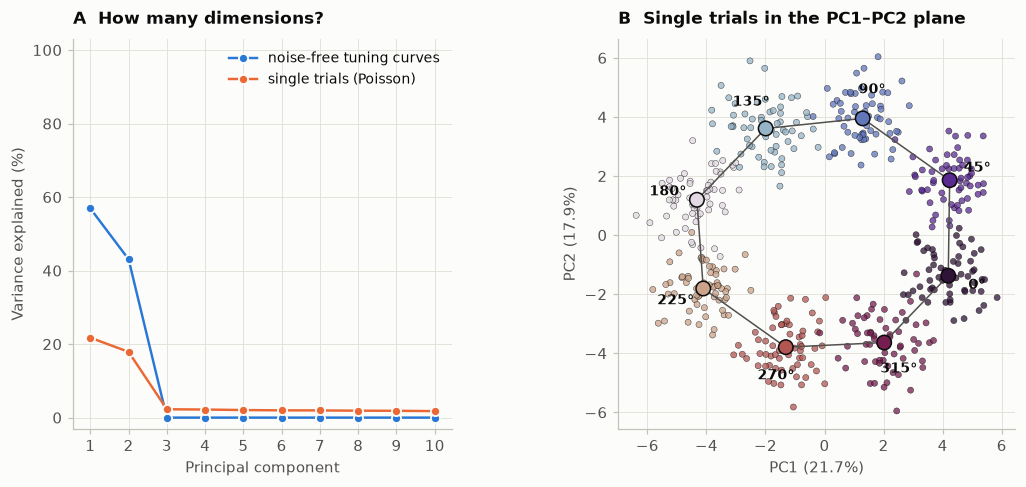

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.3})

ax = axes[0]
x = np.arange(1, 11)
ax.plot(x, ev_signal, "o-", color=C_BLUE, mec=SURFACE, mew=1.2, label="noise-free tuning curves")
ax.plot(x, ev_trials, "o-", color=C_ORANGE, mec=SURFACE, mew=1.2, label="single trials (Poisson)")
ax.set(xlabel="Principal component", ylabel="Variance explained (%)", xticks=x, ylim=(-3, 103),
       title="A  How many dimensions?")
ax.legend(loc="upper right")

ax = axes[1]
ax.scatter(pcs[:, 0], pcs[:, 1], c=stimuli[y], cmap=CYC, vmin=0, vmax=2 * np.pi,
           s=16, alpha=0.75, edgecolors=(0, 0, 0, 0.25), linewidths=0.3)
centroids = np.stack([pcs[y == k, :2].mean(0) for k in range(K)])
ring = np.vstack([centroids, centroids[:1]])
ax.plot(ring[:, 0], ring[:, 1], color=INK_2, lw=1, zorder=3)
ax.scatter(centroids[:, 0], centroids[:, 1], c=stimuli, cmap=CYC, vmin=0, vmax=2 * np.pi,
           s=90, edgecolors=INK, linewidths=1, zorder=4)
spread = np.abs(pcs[:, :2]).max()
for k, (cx, cy) in enumerate(centroids):                    # direction labels, pushed outward
    r = np.hypot(cx, cy)
    ax.text(cx + cx / r * 0.16 * spread, cy + cy / r * 0.16 * spread, f"{stim_deg[k]}°",
            fontsize=9, color=INK, ha="center", va="center", fontweight="bold", zorder=5)
ax.set(xlabel=f"PC1 ({ev_trials[0]:.1f}%)", ylabel=f"PC2 ({ev_trials[1]:.1f}%)", aspect="equal",
       title="B  Single trials in the PC1–PC2 plane")
save(fig, "fig03_pca.png")
plt.show()

**Reading Figure 3.** For the noise-free curves (A, blue) the first two PCs carry essentially all the variance, the plane predicted by the equation above. For single trials (orange) PC1 and PC2 still stand out, but the remaining PCs form a flat **noise floor**: Poisson noise is spread over every direction of the 50-D space. In B the stimulus means (large dots) sit on a ring **in the order of the directions**: neighbouring directions are neighbours in neural space, and 0° closes the loop with 315°. The single-trial clouds overlap most with their neighbours on the ring.

## 4. Decoding the stimulus with cross-validation

**Decoder.** Multinomial logistic regression on the 50 spike counts of a single trial, predicting one of the $K$ stimuli.

**Cross-validation.** Stratified $k$-fold ($k$ = 5, same number of trials per stimulus in each fold). The decoder is a Pipeline (StandardScaler → LogisticRegression), so the scaling is fitted on the training folds only; nothing from the test fold leaks into training.

**Is it above chance?** Chance is $1/K$ = 12.5 %. A permutation test refits the whole pipeline after shuffling the stimulus labels (200 times) and asks how often a shuffled-label model does as well as the real one.

In [27]:
def make_decoder():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))


def cv_accuracy(X, y, cv=CV):
    scores = cross_val_score(make_decoder(), X, y, cv=cv, scoring="accuracy")
    return scores.mean(), scores.std()


acc_pop, acc_pop_sd = cv_accuracy(X, y)
_, perm_scores, p_value = permutation_test_score(
    make_decoder(), X, y, cv=CV, n_permutations=P["n_permutations"], random_state=SEED, n_jobs=-1)
y_pred = cross_val_predict(make_decoder(), X, y, cv=CV)
conf = confusion_matrix(y, y_pred, normalize="true")

# Error distance in stimulus steps, wrapped onto the circle: 0 = correct, ±1 = neighbour, ...
step_err = (y_pred - y + K // 2) % K - K // 2
steps = np.arange(-(K // 2), K - K // 2)
err_frac = np.array([(step_err == s).mean() for s in steps])

print(f"Population ({N} neurons): CV accuracy = {acc_pop:.3f} ± {acc_pop_sd:.3f} (mean ± SD over folds)")
print(f"Shuffled-label accuracy: {perm_scores.mean():.3f} ± {perm_scores.std():.3f} | permutation p = {p_value:.4f} "
      f"(smallest possible with {P['n_permutations']} permutations: {1 / (P['n_permutations'] + 1):.4f})")
print(f"Errors that land on a neighbouring direction: {err_frac[np.abs(steps) == 1].sum() / (1 - err_frac[steps == 0][0]):.0%} of all errors")

Population (50 neurons): CV accuracy = 0.883 ± 0.036 (mean ± SD over folds)
Shuffled-label accuracy: 0.124 ± 0.019 | permutation p = 0.0050 (smallest possible with 200 permutations: 0.0050)
Errors that land on a neighbouring direction: 100% of all errors


saved → figures\fig04_decoder.png


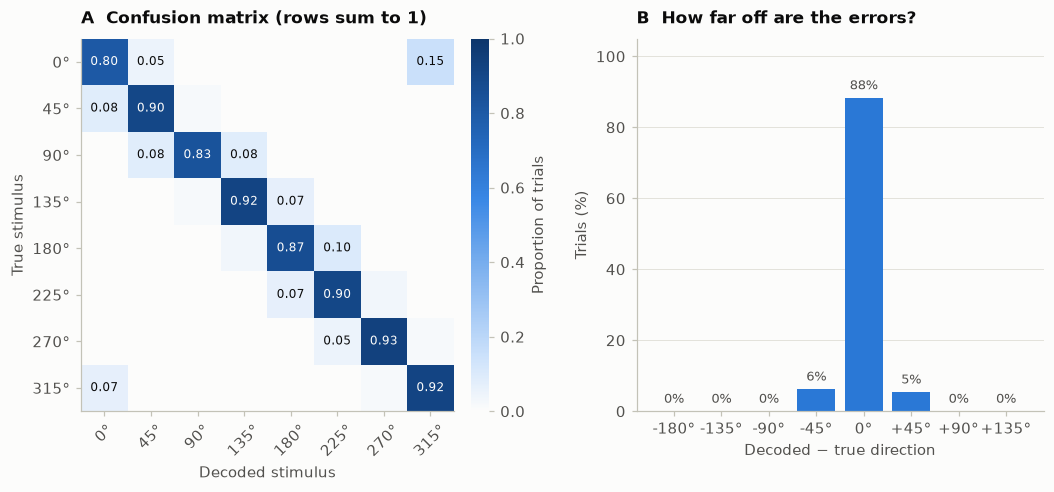

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.05, 1], "wspace": 0.35})

ax = axes[0]
im = ax.imshow(conf, cmap=SEQ, vmin=0, vmax=1, interpolation="nearest")
for i in range(K):
    for j in range(K):
        if conf[i, j] >= 0.05:
            ax.text(j, i, f"{conf[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color=SURFACE if conf[i, j] > 0.55 else INK)
labels = [f"{d}°" for d in stim_deg]
ax.set(xticks=range(K), xticklabels=labels, yticks=range(K), yticklabels=labels,
       xlabel="Decoded stimulus", ylabel="True stimulus", title="A  Confusion matrix (rows sum to 1)")
ax.tick_params(axis="x", labelrotation=45)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.set_label("Proportion of trials", color=INK_2)
cb.outline.set_visible(False)

ax = axes[1]
ax.bar(steps, 100 * err_frac, width=0.8, color=C_BLUE)
for s, v in zip(steps, err_frac):
    ax.text(s, 100 * v + 1.5, f"{100 * v:.0f}%", ha="center", va="bottom", fontsize=8.5, color=INK_2)
step_deg = 360 // K
ax.set(xticks=steps, xticklabels=[f"{s * step_deg:+d}°" if s else "0°" for s in steps],
       xlabel="Decoded − true direction", ylabel="Trials (%)", ylim=(0, 105),
       title="B  How far off are the errors?")
ax.grid(axis="x", visible=False)
save(fig, "fig04_decoder.png")
plt.show()

**Reading Figure 4.** The confusion matrix is dominated by its diagonal, and the off-diagonal mass sits next to it, including the wrap-around corners (0° ↔ 315°). Panel B makes this explicit: all (or nearly all) errors are one step (±45°) away. The decoder does not confuse random stimuli, it confuses stimuli that are **neighbours on the ring of Figure 3**, because those evoke the most similar population patterns.

## 5. One neuron vs the population

Two comparisons, both with the same decoder and the same CV folds:

1. **Every neuron alone.** Decode from each single neuron's count (50 decoders) and compare the distribution with the population accuracy.
2. **Neuron-dropping curve.** Decode from random subsets of $n$ = 1, 2, 4, …, 50 neurons (20 random subsets per size) and plot accuracy against $n$.

In [29]:
acc_single = np.array([cv_accuracy(X[:, [i]], y)[0] for i in range(N)])

sizes = [n for n in P["subset_sizes"] if n <= N]
curve = np.zeros((len(sizes), P["n_subset_draws"]))
for a, n in enumerate(sizes):
    for d in range(P["n_subset_draws"]):
        curve[a, d] = cv_accuracy(X[:, rng_sub.choice(N, n, replace=False)], y)[0]

best = int(np.argmax(acc_single))
print(f"Single neurons: mean {acc_single.mean():.3f}, best {acc_single.max():.3f} (neuron {best}), worst {acc_single.min():.3f}")
print(f"Population of {N}: {acc_pop:.3f}  →  {acc_pop / acc_single.mean():.1f}× the average single neuron")
for n, row in zip(sizes, curve):
    print(f"  n = {n:2d}: {row.mean():.3f} ± {row.std():.3f}")

Single neurons: mean 0.231, best 0.323 (neuron 45), worst 0.169
Population of 50: 0.883  →  3.8× the average single neuron
  n =  1: 0.217 ± 0.033
  n =  2: 0.314 ± 0.064
  n =  4: 0.432 ± 0.067
  n =  8: 0.586 ± 0.041
  n = 16: 0.722 ± 0.034
  n = 32: 0.837 ± 0.021
  n = 50: 0.883 ± 0.000


saved → figures\fig05_single_vs_population.png


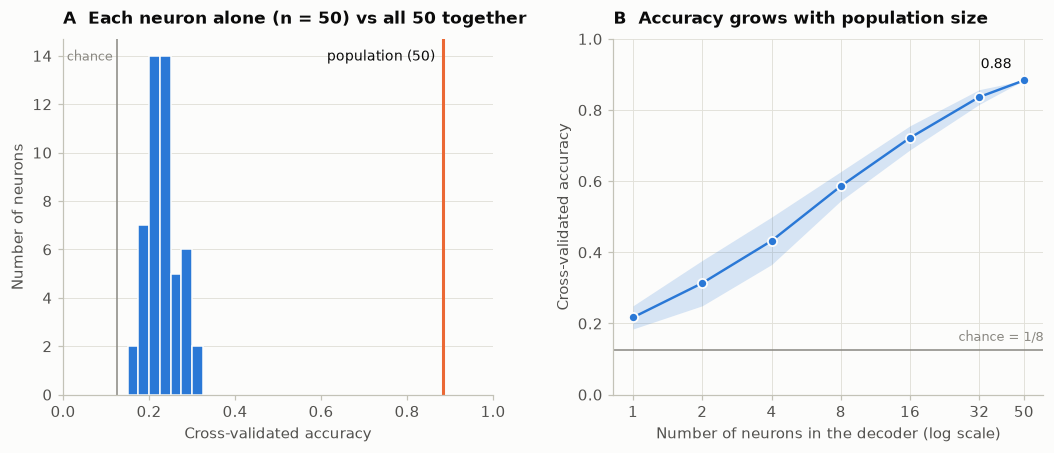

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"wspace": 0.28})

ax = axes[0]
bins = np.linspace(0, 1, 41)
ax.hist(acc_single, bins=bins, color=C_BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(CHANCE, color=MUTED, lw=1)
ax.axvline(acc_pop, color=C_ORANGE, lw=2)
ymax = ax.get_ylim()[1]
ax.text(CHANCE, ymax * 0.97, "chance ", color=MUTED, fontsize=8.5, va="top", ha="right")
ax.text(acc_pop, ymax * 0.97, f"population ({N})  ", color=INK, fontsize=9, va="top", ha="right")
ax.set(xlabel="Cross-validated accuracy", ylabel="Number of neurons", xlim=(0, 1),
       title=f"A  Each neuron alone (n = {N}) vs all {N} together")
ax.grid(axis="x", visible=False)

ax = axes[1]
m, s = curve.mean(1), curve.std(1)
ax.fill_between(sizes, m - s, m + s, color=C_BLUE, alpha=0.18, lw=0)
ax.plot(sizes, m, "o-", color=C_BLUE, mec=SURFACE, mew=1.2)
chance_line(ax, CHANCE)
ax.set_xscale("log", base=2)
ax.set(xticks=sizes, xticklabels=sizes, xlabel="Number of neurons in the decoder (log scale)",
       ylabel="Cross-validated accuracy", ylim=(0, 1), title="B  Accuracy grows with population size")
ax.annotate(f"{m[-1]:.2f}", xy=(sizes[-1], m[-1]), xytext=(-8, 8), textcoords="offset points",
            ha="right", fontsize=9, color=INK)
save(fig, "fig05_single_vs_population.png")
plt.show()

**Reading Figure 5.** Single neurons sit only a little above chance (A); even the best one is far below the population. Accuracy then climbs steadily as neurons are added (B), with diminishing returns on the log axis.

Why the population wins, using the two problems from Figure 1:

1. **Symmetry is broken.** Neurons with *different* preferred directions are confused by *different* pairs of stimuli. The ambiguity of one neuron ($\varphi - \delta$ vs $\varphi + \delta$) is resolved by another neuron whose preference sits on one side.
2. **Noise is averaged out.** Each neuron's Poisson noise is private (independent), so evidence accumulates across neurons while noise partially cancels. The section below asks what happens when this independence assumption is broken.

## Summary

In [33]:
print(f"Setup: {N} neurons, {K} directions, {P['n_trials']} trials/stimulus, T = {T} s, seed {SEED}\n")
print(f"Single neuron (mean over {N})     : {acc_single.mean():.3f}   (best {acc_single.max():.3f})")
print(f"Population of {N}, Poisson noise   : {acc_pop:.3f}   (permutation p = {p_value:.4f}; chance {CHANCE:.3f})")
print(f"Noise-free tuning: PC1 + PC2       : {ev_signal[:2].sum():.2f}% of variance")
print(f"Single trials:     PC1 + PC2       : {ev_trials[:2].sum():.1f}% of variance")

Setup: 50 neurons, 8 directions, 60 trials/stimulus, T = 0.2 s, seed 2026

Single neuron (mean over 50)     : 0.231   (best 0.323)
Population of 50, Poisson noise   : 0.883   (permutation p = 0.0050; chance 0.125)
Noise-free tuning: PC1 + PC2       : 100.00% of variance
Single trials:     PC1 + PC2       : 39.6% of variance


A single cosine-tuned neuron is a poor reporter of direction for two reasons: its tuning curve is symmetric (two directions give the same mean count) and its Poisson count is noisy. A population with heterogeneous preferred directions breaks the symmetry, and with independent noise it averages the noise away, so decoding accuracy grows with the number of neurons. The population response is low-dimensional (a ring in a 2-D plane for cosine tuning), and the decoder's mistakes reflect that geometry: errors fall on neighbouring directions. Noise correlations are not harmful in general a shared gain is nearly harmless but correlations among similarly tuned neurons align noise with the signal and limit how much adding neurons helps.

## References

- Georgopoulos, A. P., Kalaska, J. F., Caminiti, R., & Massey, J. T. (1982). On the relations between the direction of two-dimensional arm movements and cell discharge in primate motor cortex. *Journal of Neuroscience*, 2(11), 1527–1537. https://doi.org/10.1523/JNEUROSCI.02-11-01527.1982
- Pouget, A., Dayan, P., & Zemel, R. (2000). Information processing with population codes. *Nature Reviews Neuroscience*, 1(2), 125–132. https://doi.org/10.1038/35039062
- Zohary, E., Shadlen, M. N., & Newsome, W. T. (1994). Correlated neuronal discharge rate and its implications for psychophysical performance. *Nature*, 370(6485), 140–143. https://doi.org/10.1038/370140a0
- Averbeck, B. B., Latham, P. E., & Pouget, A. (2006). Neural correlations, population coding and computation. *Nature Reviews Neuroscience*, 7(5), 358–366. https://doi.org/10.1038/nrn1888
- Cohen, M. R., & Kohn, A. (2011). Measuring and interpreting neuronal correlations. *Nature Neuroscience*, 14(7), 811–819. https://doi.org/10.1038/nn.2842
- Moreno-Bote, R., Beck, J., Kanitscheider, I., Pitkow, X., Latham, P., & Pouget, A. (2014). Information-limiting correlations. *Nature Neuroscience*, 17(10), 1410–1417. https://doi.org/10.1038/nn.3807
- Cunningham, J. P., & Yu, B. M. (2014). Dimensionality reduction for large-scale neural recordings. *Nature Neuroscience*, 17(11), 1500–1509. https://doi.org/10.1038/nn.3776
- Kohn, A., Coen-Cagli, R., Kanitscheider, I., & Pouget, A. (2016). Correlations and neuronal population information. *Annual Review of Neuroscience*, 39, 237–256. https://doi.org/10.1146/annurev-neuro-070815-013851